# Tugas P2 - Representasi Data & Pra-pemrosesan
**Mata Kuliah:** Pembelajaran Mesin
**Nama :** Iqbal Firdaus 
**NIM :** 10124134
**Dataset:** Cervical Cancer (Risk Factors) dari UCI Machine Learning Repository
**Link data:** https://archive.ics.uci.edu/dataset/383/cervical+cancer+risk+factors
**Kasus:** klasifikasi biner, target `Biopsy` (0 = negatif, 1 = positif)
**Pengklasifikasi:** Support Vector Machine (SVM), karena NIM genap

### Alur praproses
1. Memuat data  →  2. Info & tipe kolom  →  3. Duplikasi  →  4. Missing values  →  5. Kolom konstan & kategori
→  6. Target & kebocoran data  →  7. Outlier (IQR)  →  8. Ketidakseimbangan kelas  →  9. Normalisasi (Min-Max)
→  10. Hasil akhir (5 teratas & 5 terbawah)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## Langkah 1 - Memuat data
File `risk_factors_cervical_cancer.csv` harus berada di folder yang sama dengan notebook.

In [2]:
DATA_FILE = "risk_factors_cervical_cancer.csv"

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(f"File tidak ditemukan: {DATA_FILE}. Letakkan di folder yang sama dengan notebook ini.")

df_raw = pd.read_csv(DATA_FILE)            
print("Ukuran data awal (baris, kolom):", df_raw.shape)
display(df_raw.head())

Ukuran data awal (baris, kolom): (858, 36)


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,IUD (years),STDs,STDs (number),STDs:condylomatosis,STDs:cervical condylomatosis,STDs:vaginal condylomatosis,STDs:vulvo-perineal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:AIDS,STDs:HIV,STDs:Hepatitis B,STDs:HPV,STDs: Number of diagnosis,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,?,?,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,?,?,0,0,0,0,0,0,0,0
2,34,1.0,?,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,?,?,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,?,?,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,?,?,0,0,0,0,0,0,0,0


## Langkah 2 - Info & tipe kolom (koreksi tipe)
Kita periksa tipe setiap kolom. Dataset ini menulis nilai yang hilang sebagai tanda **`?`**.
Akibatnya kolom yang seharusnya angka terbaca sebagai teks. SVM hanya bisa memproses angka, bukan teks,
jadi tipenya harus dikoreksi.

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858 entries, 0 to 857
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Age                                 858 non-null    int64 
 1   Number of sexual partners           858 non-null    object
 2   First sexual intercourse            858 non-null    object
 3   Num of pregnancies                  858 non-null    object
 4   Smokes                              858 non-null    object
 5   Smokes (years)                      858 non-null    object
 6   Smokes (packs/year)                 858 non-null    object
 7   Hormonal Contraceptives             858 non-null    object
 8   Hormonal Contraceptives (years)     858 non-null    object
 9   IUD                                 858 non-null    object
 10  IUD (years)                         858 non-null    object
 11  STDs                                858 non-null    object

In [4]:
# Berapa banyak tanda '?' di tiap kolom?
jumlah_tanya = (df_raw == "?").sum()
jumlah_tanya = jumlah_tanya[jumlah_tanya > 0]
print("Kolom yang mengandung '?':", len(jumlah_tanya))
print("Total sel bertanda '?':", int(jumlah_tanya.sum()))

# Kolom yang tipenya perlu dikoreksi = kolom non-angka di data mentah
kolom_teks = [c for c in df_raw.columns if not pd.api.types.is_numeric_dtype(df_raw[c])]
print("Kolom bertipe teks yang perlu dikoreksi:", len(kolom_teks))

Kolom yang mengandung '?': 26
Total sel bertanda '?': 3622
Kolom bertipe teks yang perlu dikoreksi: 26


In [5]:
# Koreksi: '?' -> NaN (nilai kosong), lalu ubah semua kolom menjadi angka
df = df_raw.replace("?", np.nan)
for c in df.columns:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Pemeriksaan: jumlah NaN baru harus sama persis dengan jumlah '?' tadi (tidak ada data rusak lain)
assert int(df.isna().sum().sum()) == int(jumlah_tanya.sum())

print("Tipe kolom setelah koreksi:")
print(df.dtypes.value_counts())

Tipe kolom setelah koreksi:
float64    26
int64      10
Name: count, dtype: int64


### Jenis data berdasarkan skala pengukuran
| Kelompok kolom | Contoh | Skala pengukuran | Perlakuan untuk SVM |
|---|---|---|---|
| Usia & hitungan/durasi | `Age`, `Number of sexual partners`, `First sexual intercourse`, `Num of pregnancies`, `Smokes (years)`, `Smokes (packs/year)`, `Hormonal Contraceptives (years)`, `IUD (years)`, `STDs (number)`, `STDs: Number of diagnosis` | **Rasio** (punya nol mutlak) | Perlu normalisasi |
| Penanda ya/tidak (0/1) | `Smokes`, `Hormonal Contraceptives`, `IUD`, `STDs`, `STDs:condylomatosis`, `STDs:syphilis`, `STDs:HIV`, dst. | **Nominal** (biner) | Sudah 0/1, tidak perlu diskalakan |
| Target | `Biopsy` | **Nominal** (biner) | Label kelas, bukan fitur |

Tidak ada kolom berskala ordinal maupun interval pada dataset ini.

## Langkah 3 - Duplikasi
Baris yang sama persis dengan baris lain membuat satu data terhitung dua kali, sehingga memengaruhi
bidang pemisah SVM. Duplikat diperiksa **sebelum** pengisian nilai kosong supaya nilai
pengganti tidak menciptakan "duplikat palsu".

In [6]:
jumlah_duplikat = int(df.duplicated().sum())
print("Jumlah baris duplikat:", jumlah_duplikat)

contoh = df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(4)
print("Contoh baris duplikat (kolom pertama saja):")
display(contoh.iloc[:, :8])

df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran data setelah menghapus duplikat:", df.shape)

Jumlah baris duplikat: 23
Contoh baris duplikat (kolom pertama saja):


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0
440,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0
454,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0
466,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0


Ukuran data setelah menghapus duplikat: (835, 36)


## Langkah 4 - Missing values
Strategi:
- Kolom yang hilang **lebih dari 90%** dibuang. Mengisinya berarti mengarang data.
- Kolom angka (usia, jumlah, durasi) yang hilang sedikit diisi **median** karena tidak terpengaruh nilai ekstrem.
- Kolom biner 0/1 yang hilang sedikit diisi **modus** (nilai terbanyak), karena median/rata-rata tidak bermakna pada 0/1.

In [7]:
hilang = df.isna().sum()
tabel_hilang = pd.DataFrame({"jumlah_hilang": hilang, "persen": (hilang / len(df) * 100).round(1)})
tabel_hilang = tabel_hilang[tabel_hilang.jumlah_hilang > 0].sort_values("persen", ascending=False)
display(tabel_hilang)

,jumlah_hilang,persen
STDs: Time since first diagnosis,764,91.5
STDs: Time since last diagnosis,764,91.5
IUD (years),112,13.4
IUD,112,13.4
Hormonal Contraceptives,103,12.3
Hormonal Contraceptives (years),103,12.3
STDs (number),100,12.0
STDs,100,12.0
STDs:vulvo-perineal condylomatosis,100,12.0
STDs:vaginal condylomatosis,100,12.0


In [8]:
# a) Buang kolom dengan missing > 90%
AMBANG = 90
kolom_buang_hilang = tabel_hilang[tabel_hilang.persen > AMBANG].index.tolist()
print("Kolom dibuang (missing >", AMBANG, "%):", kolom_buang_hilang)
df = df.drop(columns=kolom_buang_hilang)

# b) Isi sisanya: modus untuk kolom biner (0/1), median untuk kolom angka lain
kolom_biner = [c for c in df.columns if set(df[c].dropna().unique()) <= {0, 1}]
diisi_modus, diisi_median = [], []
for c in df.columns[df.isna().any()]:
    if c in kolom_biner:
        df[c] = df[c].fillna(df[c].mode()[0]);  diisi_modus.append(c)
    else:
        df[c] = df[c].fillna(df[c].median());   diisi_median.append(c)

print("Diisi median:", diisi_median)
print("Diisi modus :", len(diisi_modus), "kolom biner")
print("Sisa nilai kosong:", int(df.isna().sum().sum()))

Kolom dibuang (missing > 90 %): ['STDs: Time since first diagnosis', 'STDs: Time since last diagnosis']
Diisi median: ['Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives (years)', 'IUD (years)', 'STDs (number)']
Diisi modus : 16 kolom biner
Sisa nilai kosong: 0


## Langkah 5 - Kolom konstan & kategori
- **Kolom konstan** (hanya satu nilai) tidak membantu membedakan data, jadi dibuang.
- **Kategori:** semua kolom pada dataset ini sudah berupa kode angka (0/1), bukan teks, sehingga tidak ada
  masalah ejaan atau kapitalisasi. Kita buktikan dengan memeriksa nilai unik tiap kolom biner.

In [9]:
kolom_konstan = [c for c in df.columns if df[c].nunique() == 1]
print("Kolom konstan yang dibuang:", kolom_konstan)
df = df.drop(columns=kolom_konstan)

# Pemeriksaan kategori: semua kolom biner hanya boleh berisi 0 dan 1
kolom_biner = [c for c in df.columns if set(df[c].unique()) <= {0, 1}]
print("Jumlah kolom biner:", len(kolom_biner))
print("Nilai unik gabungan seluruh kolom biner:", sorted(set(np.concatenate([df[c].unique() for c in kolom_biner]))))
print("-> Tidak ada ejaan/kapitalisasi yang perlu diperbaiki (semua sudah kode 0/1).")

Kolom konstan yang dibuang: ['STDs:cervical condylomatosis', 'STDs:AIDS']
Jumlah kolom biner: 22
Nilai unik gabungan seluruh kolom biner: [np.float64(0.0), np.float64(1.0)]
-> Tidak ada ejaan/kapitalisasi yang perlu diperbaiki (semua sudah kode 0/1).


## Langkah 6 - Menentukan target & indikasi kebocoran data (leakage)
Dataset punya **empat** kolom target (`Hinselmann`, `Schiller`, `Citology`, `Biopsy`) dan empat kolom
`Dx*` (hasil diagnosis dokter). Kita pilih **`Biopsy`** sebagai label karena biopsi adalah standar acuan diagnosis.

**Kebocoran data** terjadi bila fitur memuat informasi yang baru diketahui *setelah* hasil yang ingin diprediksi.
Tiga target lain dan kolom `Dx*` adalah hasil pemeriksaan, jadi tidak boleh menjadi fitur.

In [10]:
TARGET = "Biopsy"
target_lain = ["Hinselmann", "Schiller", "Citology"]
kolom_dx = ["Dx:Cancer", "Dx:CIN", "Dx:HPV", "Dx"]
kolom_bocor = target_lain + kolom_dx

# Bukti indikasi kebocoran: kaitan kolom-kolom ini dengan target
print("Korelasi dengan Biopsy:")
print(df[kolom_bocor + [TARGET]].corr()[TARGET].drop(TARGET).round(3))

print("\nTabel silang Biopsy vs Dx:Cancer (hasil diagnosis tidak tersedia sebelum pemeriksaan):")
display(pd.crosstab(df[TARGET], df["Dx:Cancer"], rownames=["Biopsy"], colnames=["Dx:Cancer"]))

Korelasi dengan Biopsy:
Hinselmann    0.552
Schiller      0.729
Citology      0.313
Dx:Cancer     0.162
Dx:CIN        0.114
Dx:HPV        0.162
Dx            0.159
Name: Biopsy, dtype: float64

Tabel silang Biopsy vs Dx:Cancer (hasil diagnosis tidak tersedia sebelum pemeriksaan):


Dx:Cancer,0,1
Biopsy,,
0,769,12
1,48,6


In [11]:
df = df.drop(columns=kolom_bocor)

fitur = [c for c in df.columns if c != TARGET]
print("Jumlah fitur:", len(fitur))
print("Daftar fitur:")
for i, c in enumerate(fitur, 1):
    print(f"{i:>2}. {c}")

Jumlah fitur: 24
Daftar fitur:
 1. Age
 2. Number of sexual partners
 3. First sexual intercourse
 4. Num of pregnancies
 5. Smokes
 6. Smokes (years)
 7. Smokes (packs/year)
 8. Hormonal Contraceptives
 9. Hormonal Contraceptives (years)
10. IUD
11. IUD (years)
12. STDs
13. STDs (number)
14. STDs:condylomatosis
15. STDs:vaginal condylomatosis
16. STDs:vulvo-perineal condylomatosis
17. STDs:syphilis
18. STDs:pelvic inflammatory disease
19. STDs:genital herpes
20. STDs:molluscum contagiosum
21. STDs:HIV
22. STDs:Hepatitis B
23. STDs:HPV
24. STDs: Number of diagnosis


## Langkah 7 - Outlier dengan IQR
**IQR** = Q3 − Q1 (lebar rentang tempat separuh data berkumpul). Nilai dianggap outlier bila berada di luar
**[Q1 − 1,5×IQR , Q3 + 1,5×IQR]**.

Kita periksa tiga kolom:
- `Age` → outlier **dideteksi dengan IQR**, lalu **dipotong (capping) ke batas IQR itu sendiri**: nilai di bawah
  batas bawah diganti batas bawah, nilai di atas batas atas diganti batas atas. Baris tidak dihapus.
- `Number of sexual partners` → outlier **hanya dilaporkan**, nilai tidak diubah.
- `Smokes (packs/year)` → ditunjukkan bahwa IQR **tidak cocok** karena sebagian besar nilainya 0.

In [12]:
def batas_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5 * iqr, q3 + 1.5 * iqr

ringkas = []
for c in ["Age", "Number of sexual partners", "Smokes (packs/year)"]:
    q1, q3, iqr, bawah, atas = batas_iqr(df[c])
    n_out = int(((df[c] < bawah) | (df[c] > atas)).sum())
    ringkas.append([c, q1, q3, iqr, bawah, atas, df[c].min(), df[c].max(), n_out])
display(pd.DataFrame(ringkas, columns=["kolom", "Q1", "Q3", "IQR", "batas_bawah", "batas_atas", "min", "maks", "jumlah_outlier"]))
print("Catatan: pada 'Smokes (packs/year)' IQR = 0 sehingga semua perokok ikut terhitung outlier.")
print("Itu bukan data aneh, hanya kelompok yang berbeda -> IQR tidak dipakai untuk kolom ini.")

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,min,maks,jumlah_outlier
0,Age,21.0,32.0,11.0,4.5,48.5,13.0,84.0,11
1,Number of sexual partners,2.0,3.0,1.0,0.5,4.5,1.0,28.0,68
2,Smokes (packs/year),0.0,0.0,0.0,0.0,0.0,0.0,37.0,123


Catatan: pada 'Smokes (packs/year)' IQR = 0 sehingga semua perokok ikut terhitung outlier.
Itu bukan data aneh, hanya kelompok yang berbeda -> IQR tidak dipakai untuk kolom ini.


Batas IQR Age: 4.5 sampai 48.5
Usia ekstrem sebelum dipotong: [49, 50, 51, 52, 59, 70, 79, 84]
Baris yang terpotong: 11 | usia min/maks sebelum: 13/84 | sesudah: 13.0/48.5


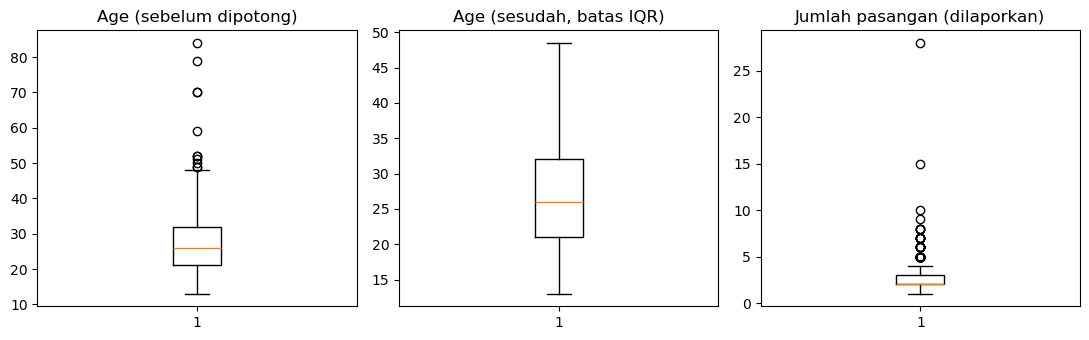

In [13]:
# Tangani outlier 'Age': potong ke batas IQR (capping)
_, _, _, BAWAH, ATAS = batas_iqr(df["Age"])
print(f"Batas IQR Age: {BAWAH} sampai {ATAS}")
age_sebelum = df["Age"].copy()
n_terpotong = int(((df["Age"] < BAWAH) | (df["Age"] > ATAS)).sum())
print("Usia ekstrem sebelum dipotong:", sorted(age_sebelum[age_sebelum > ATAS].unique().tolist()))
df["Age"] = df["Age"].clip(lower=BAWAH, upper=ATAS)
print(f"Baris yang terpotong: {n_terpotong} | usia min/maks sebelum: {age_sebelum.min()}/{age_sebelum.max()} "
      f"| sesudah: {df['Age'].min()}/{df['Age'].max()}")

fig, ax = plt.subplots(1, 3, figsize=(11, 3.5))
ax[0].boxplot(age_sebelum);                 ax[0].set_title("Age (sebelum dipotong)")
ax[1].boxplot(df["Age"]);                   ax[1].set_title("Age (sesudah, batas IQR)")
ax[2].boxplot(df["Number of sexual partners"]); ax[2].set_title("Jumlah pasangan (dilaporkan)")
plt.tight_layout(); plt.show()

## Langkah 8 - Ketidakseimbangan kelas
Bila satu kelas jauh lebih sedikit, bidang pemisah SVM cenderung condong ke kelas mayoritas karena
kesalahan pada kelas itu lebih banyak. Di tahap ini kita hanya **memeriksa dan melaporkan** distribusinya.

,jumlah,persen
Biopsy,,
0,781,93.53
1,54,6.47


Rasio kelas negatif : positif = 14.5 : 1
Akurasi bila selalu menebak 'negatif': 93.5%  (terlihat bagus, tetapi menyesatkan)


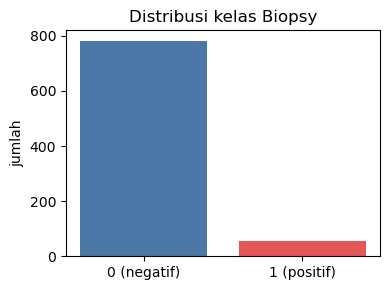

In [14]:
dist = df[TARGET].value_counts().sort_index()
persen = (dist / dist.sum() * 100).round(2)
display(pd.DataFrame({"jumlah": dist, "persen": persen}))
print(f"Rasio kelas negatif : positif = {dist[0] / dist[1]:.1f} : 1")
print(f"Akurasi bila selalu menebak 'negatif': {dist[0] / dist.sum() * 100:.1f}%  (terlihat bagus, tetapi menyesatkan)")

plt.figure(figsize=(4, 3))
plt.bar(["0 (negatif)", "1 (positif)"], dist.values, color=["#4C78A8", "#E45756"])
plt.title("Distribusi kelas Biopsy"); plt.ylabel("jumlah"); plt.tight_layout(); plt.show()

**Catatan untuk tahap pemodelan:** gunakan pembagian data berstrata (`stratify=y`) dan ukuran evaluasi selain akurasi
(recall, precision, F1). Teknik penyeimbangan seperti SMOTE, bila dipakai, hanya diterapkan pada **data latih**.

## Langkah 9 - Normalisasi (Min-Max)
Rumus: **x' = (x − x_min) / (x_maks − x_min)**, sehingga semua nilai berada di rentang 0 sampai 1.

SVM sensitif pada skala fitur, jadi kolom berskala besar (misalnya usia) akan mendominasi kolom 0/1. Min-Max dipilih karena
membuat kolom angka berada pada rentang yang sama dengan kolom biner (0 sampai 1). Kolom biner **tidak perlu**
diskalakan.

*Catatan:* pada tahap pemodelan, `MinMaxScaler` sebaiknya di-*fit* hanya pada data latih agar tidak terjadi
kebocoran dari data uji.

In [15]:
kolom_biner_fitur = [c for c in fitur if set(df[c].unique()) <= {0, 1}]
kolom_skala = [c for c in fitur if c not in kolom_biner_fitur]
print("Kolom yang dinormalisasi:", kolom_skala)
print("Kolom biner (tidak diubah):", len(kolom_biner_fitur), "kolom")

X = df[fitur].copy()
y = df[TARGET].copy()

scaler = MinMaxScaler()
X[kolom_skala] = scaler.fit_transform(X[kolom_skala])

# Pemeriksaan: semua kolom hasil skala harus berada pada 0..1
print("Min/maks seluruh fitur setelah normalisasi:", X.min().min(), "/", X.max().max())

Kolom yang dinormalisasi: ['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives (years)', 'IUD (years)', 'STDs (number)', 'STDs: Number of diagnosis']
Kolom biner (tidak diubah): 14 kolom
Min/maks seluruh fitur setelah normalisasi: 0.0 / 1.0


## Langkah 10 - Hasil akhir: 5 teratas dan 5 terbawah

In [16]:
df_akhir = pd.concat([X, y], axis=1)
print("Ukuran data akhir (baris, kolom):", df_akhir.shape, "-> 24 fitur + 1 target")

print("\n5 DATA TERATAS:")
display(df_akhir.head(5))

print("\n5 DATA TERBAWAH:")
display(df_akhir.tail(5))

Ukuran data akhir (baris, kolom): (835, 25) -> 24 fitur + 1 target

5 DATA TERATAS:


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,IUD (years),STDs,STDs (number),STDs:condylomatosis,STDs:vaginal condylomatosis,STDs:vulvo-perineal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:HIV,STDs:Hepatitis B,STDs:HPV,STDs: Number of diagnosis,Biopsy
0,0.140845,0.111111,0.227273,0.090909,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,0.056338,0.000000,0.181818,0.090909,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,0.591549,0.000000,0.318182,0.090909,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,1.000000,0.148148,0.272727,0.363636,1.0,1.0,1.0,1.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,0.929577,0.074074,0.500000,0.363636,0.0,0.0,0.0,1.0,0.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0



5 DATA TERBAWAH:


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,IUD (years),STDs,STDs (number),STDs:condylomatosis,STDs:vaginal condylomatosis,STDs:vulvo-perineal condylomatosis,STDs:syphilis,STDs:pelvic inflammatory disease,STDs:genital herpes,STDs:molluscum contagiosum,STDs:HIV,STDs:Hepatitis B,STDs:HPV,STDs: Number of diagnosis,Biopsy
830,0.591549,0.074074,0.363636,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
831,0.535211,0.037037,0.409091,0.090909,0.0,0.0,0.0,1.0,0.266667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
832,0.338028,0.037037,0.318182,0.000000,0.0,0.0,0.0,1.0,0.002667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
833,0.563380,0.037037,0.636364,0.181818,0.0,0.0,0.0,1.0,0.002667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
834,0.450704,0.037037,0.454545,0.090909,0.0,0.0,0.0,1.0,0.016667,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [17]:
# Ringkasan sebelum vs sesudah praproses
ringkasan = pd.DataFrame({
    "Tahap": ["Data awal", "Setelah hapus duplikat", "Data akhir (fitur + target)"],
    "Baris": [df_raw.shape[0], df_raw.shape[0] - jumlah_duplikat, df_akhir.shape[0]],
    "Kolom": [df_raw.shape[1], df_raw.shape[1], df_akhir.shape[1]],
})
display(ringkasan)

df_akhir.to_csv("cervical_cancer_preprocessed.csv", index=False)
print("Disimpan: cervical_cancer_preprocessed.csv")

,Tahap,Baris,Kolom
0,Data awal,858,36
1,Setelah hapus duplikat,835,36
2,Data akhir (fitur + target),835,25


Disimpan: cervical_cancer_preprocessed.csv
